In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sbs

In [2]:
df = pd.read_csv('../data/community.csv')
df

,ปี,เดือน,จังหวัด,อำเภอ,อปท.,ขยะมูลฝอยชุมชน(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,189.12
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,123.84
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,154.2
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,232.13
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,642.67
...,...,...,...,...,...,...
2650,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,750.775
2651,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,716.215
2652,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,เทศบาลเมืองบางศรีเมือง,"1,098.55"
2653,2567,ธันวาคม,นนทบุรี,เมืองนนทบุรี,อบต.บางไผ่,441.42


In [3]:
df.head()

,ปี,เดือน,จังหวัด,อำเภอ,อปท.,ขยะมูลฝอยชุมชน(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,189.12
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,123.84
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,154.2
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,232.13
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,642.67


In [4]:
df.isnull().sum()

ปี                     0
เดือน                  0
จังหวัด                0
อำเภอ                  0
อปท.                   0
ขยะมูลฝอยชุมชน(ตัน)    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ปี                   2655 non-null   int64
 1   เดือน                2655 non-null   str  
 2   จังหวัด              2655 non-null   str  
 3   อำเภอ                2655 non-null   str  
 4   อปท.                 2655 non-null   str  
 5   ขยะมูลฝอยชุมชน(ตัน)  2655 non-null   str  
dtypes: int64(1), str(5)
memory usage: 124.6 KB


In [7]:
df['ขยะมูลฝอยชุมชน(ตัน)'] = df['ขยะมูลฝอยชุมชน(ตัน)'].str.replace(',', '').astype(float)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ปี                   2655 non-null   int64  
 1   เดือน                2655 non-null   str    
 2   จังหวัด              2655 non-null   str    
 3   อำเภอ                2655 non-null   str    
 4   อปท.                 2655 non-null   str    
 5   ขยะมูลฝอยชุมชน(ตัน)  2655 non-null   float64
dtypes: float64(1), int64(1), str(4)
memory usage: 124.6 KB


In [8]:
for col in df.columns[1:5]:
    df[col] = df[col].astype('category')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   ปี                   2655 non-null   int64   
 1   เดือน                2655 non-null   category
 2   จังหวัด              2655 non-null   category
 3   อำเภอ                2655 non-null   category
 4   อปท.                 2655 non-null   category
 5   ขยะมูลฝอยชุมชน(ตัน)  2655 non-null   float64 
dtypes: category(4), float64(1), int64(1)
memory usage: 52.5 KB


In [9]:
df.loc[df["ขยะมูลฝอยชุมชน(ตัน)"] > 100_000, "ขยะมูลฝอยชุมชน(ตัน)"] = df.loc[df["ขยะมูลฝอยชุมชน(ตัน)"] > 100_000, "ขยะมูลฝอยชุมชน(ตัน)"] / 1000

In [10]:
# 1. หาค่ากลาง (Median) ปกติของเทศบาลนครปากเกร็ด (ไม่รวมเดือนที่มีปัญหา)
pakkret_normal_median = df[(df['อปท.'] == 'เทศบาลนครปากเกร็ด') & (df['ขยะมูลฝอยชุมชน(ตัน)'] < 20000)]['ขยะมูลฝอยชุมชน(ตัน)'].median()

# 2. แก้ไขเฉพาะจุดที่ดีดไป 72,135 ให้กลับมาเป็นค่ากลางปกติ
df.loc[(df['อปท.'] == 'เทศบาลนครปากเกร็ด') & (df['ขยะมูลฝอยชุมชน(ตัน)'] > 70000), 'ขยะมูลฝอยชุมชน(ตัน)'] = pakkret_normal_median

In [11]:
# 2. คำนวณหาค่ากลาง (Median) ของแต่ละ อปท. แยกจากกัน
# วิธีนี้ทำให้ อบต.เล็ก และ เทศบาลใหญ่ มีเกณฑ์ตรวจจับที่เป็นธรรมกับขนาดตัวเอง
df['median_waste'] = df.groupby('อปท.')['ขยะมูลฝอยชุมชน(ตัน)'].transform('median')

# 3. ตั้งเงื่อนไข: ถ้าค่าขยะในเดือนนั้น "สูงเกิน 4 เท่าของค่ากลางตัวเอง" 
# และมีปริมาณมากกว่า 1,000 ตัน (เพื่อป้องกันการปรับค่าใน อปท. ที่เล็กมากๆ จนเกินไป)
condition = (df['ขยะมูลฝอยชุมชน(ตัน)'] > df['median_waste'] * 4) & (df['ขยะมูลฝอยชุมชน(ตัน)'] > 1000)

# เช็คยอดก่อนแก้
outlier_count = df[condition].shape[0]
print(f"พบข้อมูลโดดผิดปกติที่ต้องแก้ไขทั้งหมด: {outlier_count} แถว")

# 4. ทำการแทนที่ (Clean) ค่าที่โดดเหล่านั้นด้วยค่า Median ปกติของ อปท. นั้นๆ
df.loc[condition, 'ขยะมูลฝอยชุมชน(ตัน)'] = df.loc[condition, 'median_waste']

# ลบคอลัมน์ที่สร้างมาช่วยคำนวณทิ้งเพื่อให้ไฟล์สะอาด
df = df.drop(columns=['median_waste'])

พบข้อมูลโดดผิดปกติที่ต้องแก้ไขทั้งหมด: 63 แถว


In [12]:
df.to_csv('../clean_data/clean_community.csv')

In [13]:

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')

# ตั้งค่าฟอนต์ภาษาไทย
thai_fonts = ['Tahoma', 'Leelawadee UI', 'Leelawadee', 'TH Sarabun New', 'Browallia New', 'Cordia New']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')

plt.rcParams['font.family'] = thai_font
plt.rcParams['axes.unicode_minus'] = False

print(f'ใช้ฟอนต์: {thai_font}')


ใช้ฟอนต์: Tahoma


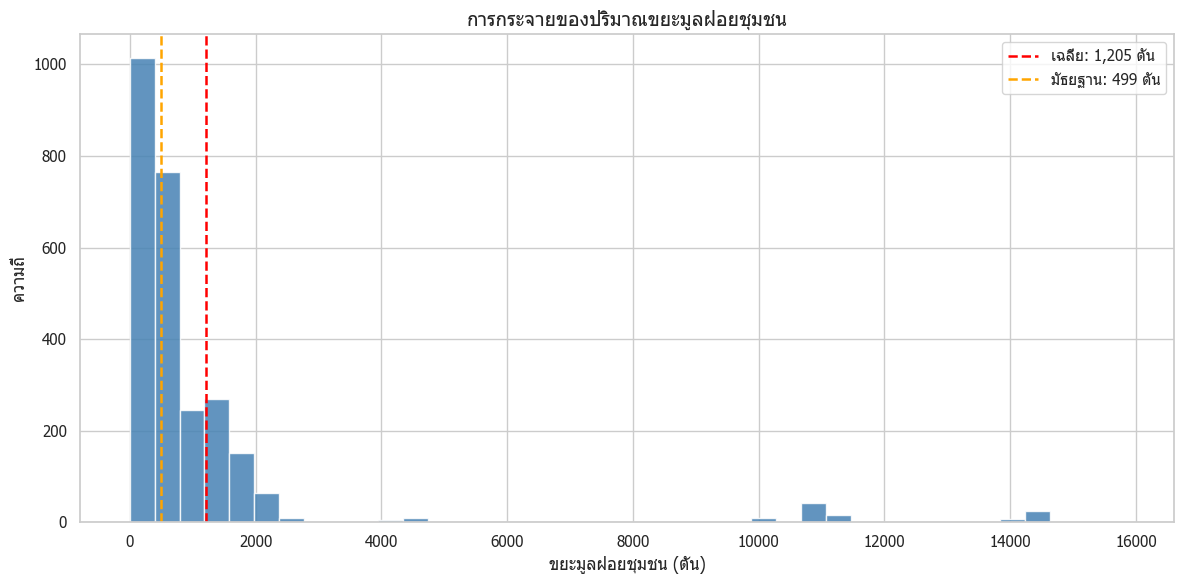

In [14]:

# Histogram: การกระจายของปริมาณขยะมูลฝอยชุมชน
col = 'ขยะมูลฝอยชุมชน(ตัน)'
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(df[col], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(df[col].mean(),   color='red',    linestyle='--', linewidth=1.8, label=f"เฉลี่ย: {df[col].mean():,.0f} ตัน")
ax.axvline(df[col].median(), color='orange', linestyle='--', linewidth=1.8, label=f"มัธยฐาน: {df[col].median():,.0f} ตัน")
ax.set_title('การกระจายของปริมาณขยะมูลฝอยชุมชน', fontsize=14)
ax.set_xlabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.set_ylabel('ความถี่')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()


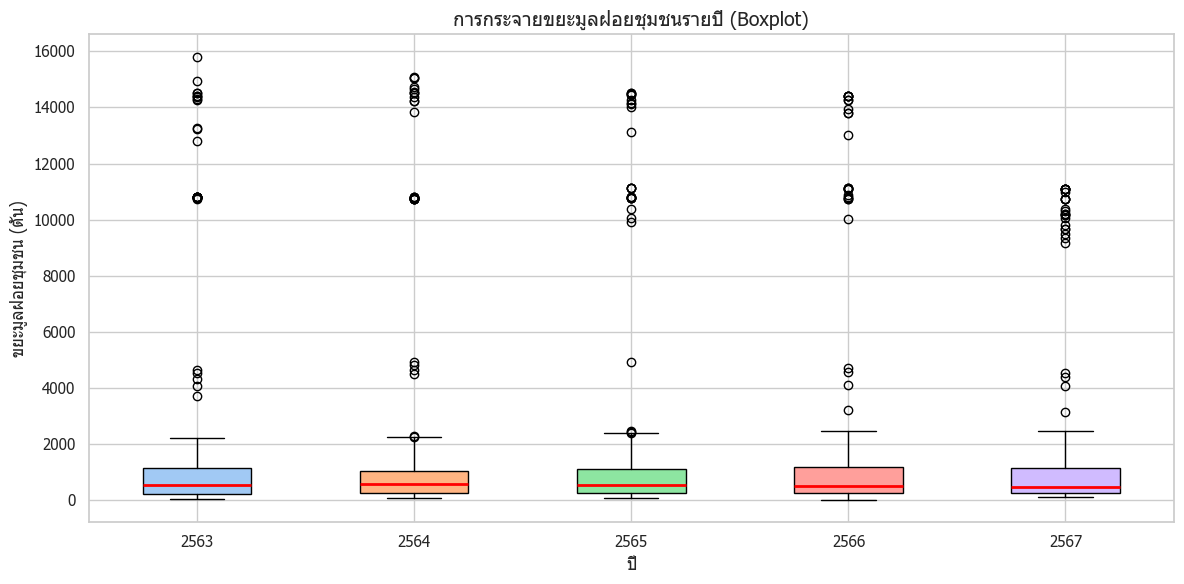

In [15]:

# Boxplot: การกระจายขยะมูลฝอยชุมชนรายปี
years = sorted(df['ปี'].unique())
data_by_year = [df[df['ปี'] == y]['ขยะมูลฝอยชุมชน(ตัน)'].values for y in years]
fig, ax = plt.subplots(figsize=(12, 6))
bp = ax.boxplot(data_by_year, labels=years, patch_artist=True,
                medianprops=dict(color='red', linewidth=2))
colors = sns.color_palette('pastel', len(years))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
ax.set_title('การกระจายขยะมูลฝอยชุมชนรายปี (Boxplot)', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
plt.tight_layout()
plt.show()


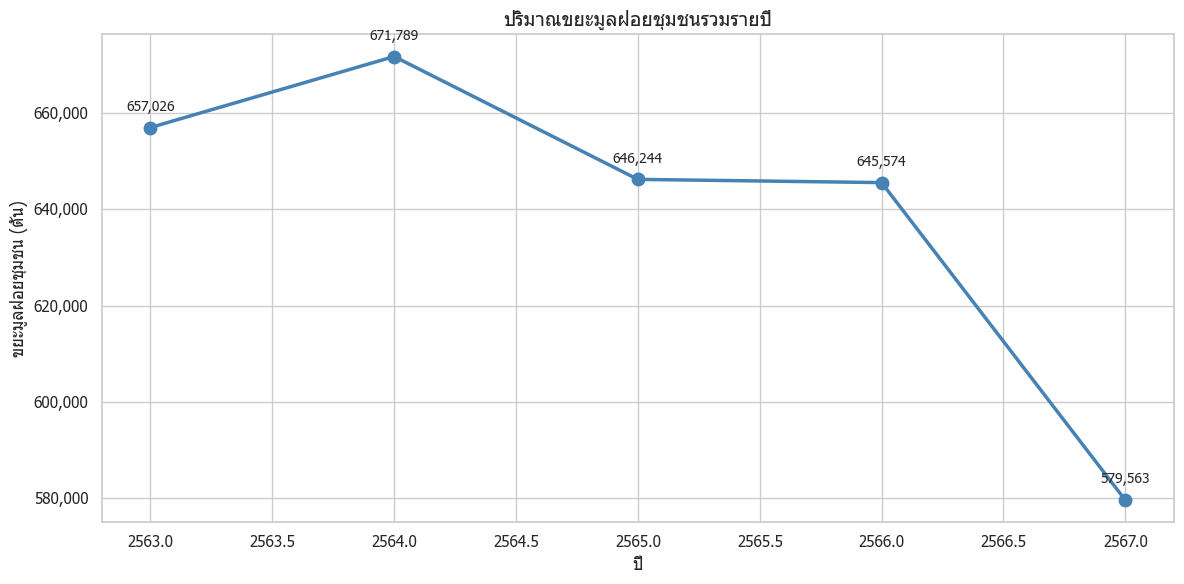

In [16]:

# Line Chart: ปริมาณขยะมูลฝอยชุมชนรวมรายปี
yearly = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum()
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(yearly.index, yearly.values, marker='o', linewidth=2.5, color='steelblue', markersize=9)
for x, y in zip(yearly.index, yearly.values):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 12), ha='center', fontsize=10)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนรวมรายปี', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


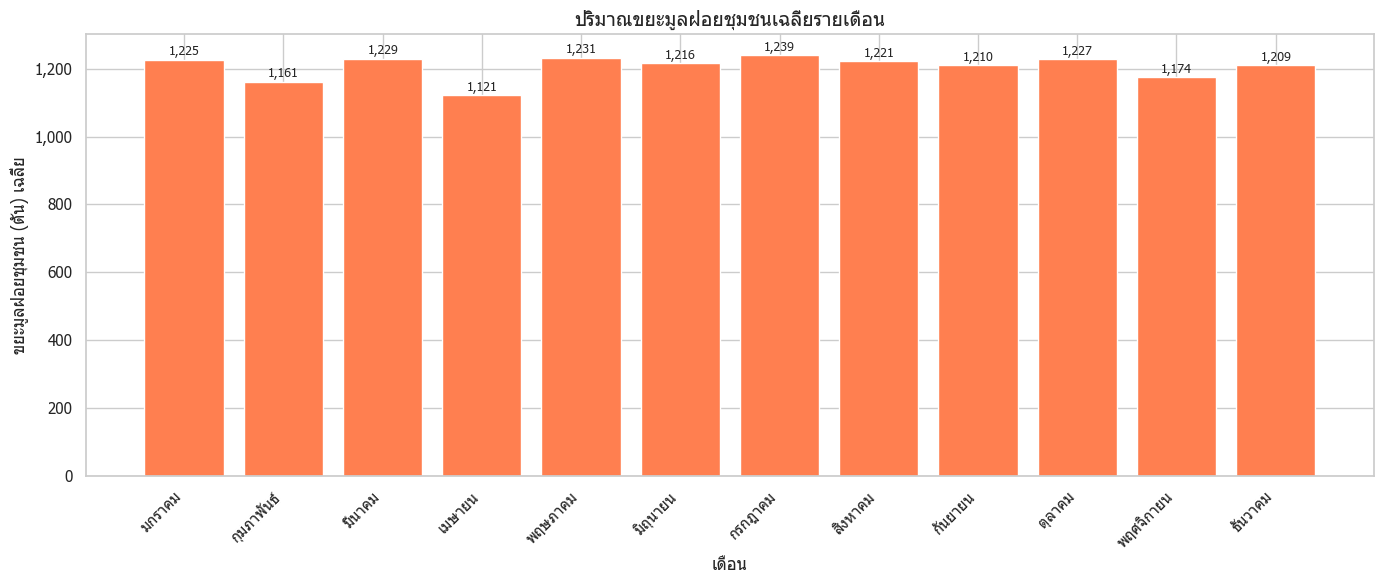

In [17]:

# Bar Chart: ปริมาณขยะมูลฝอยชุมชนเฉลี่ยรายเดือน
month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
monthly_avg = df.groupby('เดือน', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].mean().reindex(month_order)
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(12), monthly_avg.values, color='coral', edgecolor='white')
ax.set_xticks(range(12))
ax.set_xticklabels(month_order, rotation=45, ha='right')
for i, v in enumerate(monthly_avg.values):
    ax.text(i, v + 5, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนเฉลี่ยรายเดือน', fontsize=14)
ax.set_xlabel('เดือน')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน) เฉลี่ย')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


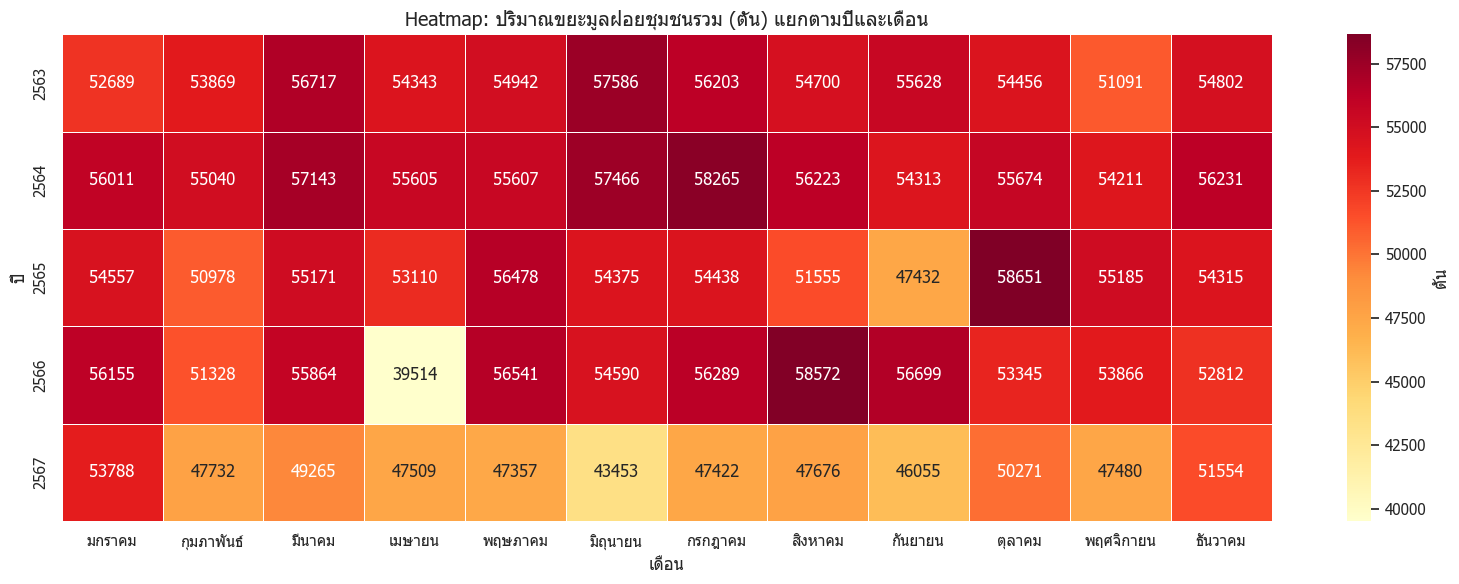

In [18]:

# Heatmap: ปริมาณขยะมูลฝอยชุมชนรวม แยกตามปีและเดือน
month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
pivot = (df.groupby(['ปี', 'เดือน'], observed=True)['ขยะมูลฝอยชุมชน(ตัน)']
         .sum().unstack('เดือน').reindex(columns=month_order))
fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, cbar_kws={'label': 'ตัน'})
ax.set_title('Heatmap: ปริมาณขยะมูลฝอยชุมชนรวม (ตัน) แยกตามปีและเดือน', fontsize=14)
ax.set_xlabel('เดือน')
ax.set_ylabel('ปี')
plt.tight_layout()
plt.show()


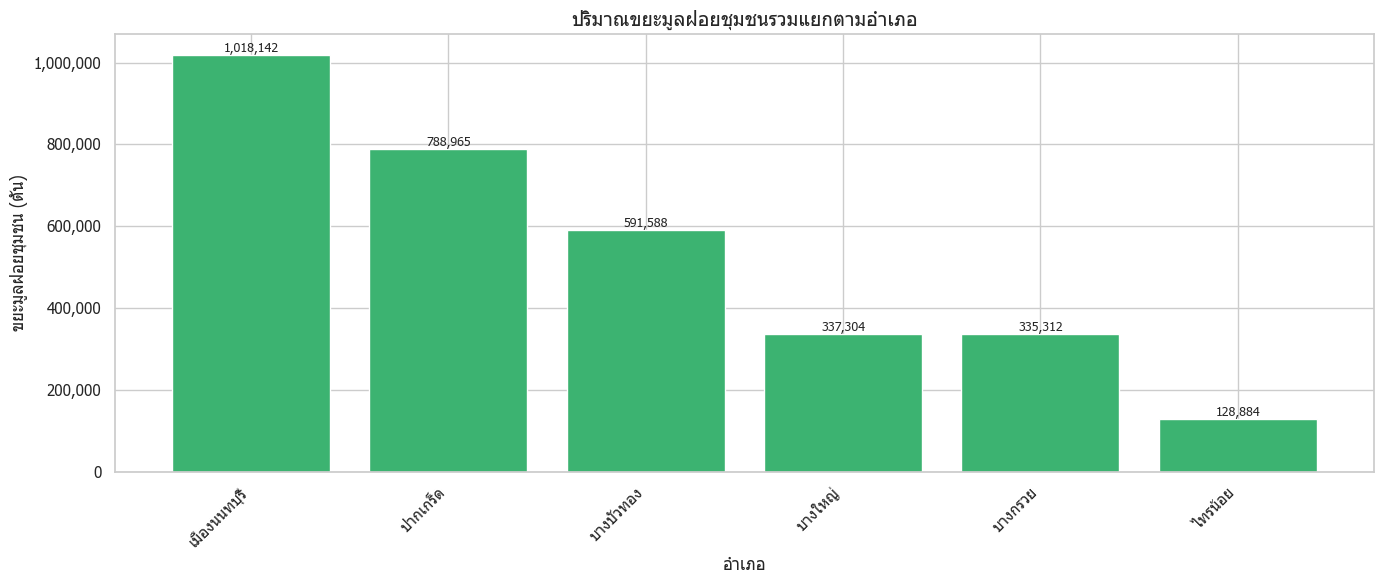

In [19]:

# Bar Chart: ปริมาณขยะมูลฝอยชุมชนรวมแยกตามอำเภอ
district_total = df.groupby('อำเภอ', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(len(district_total)), district_total.values, color='mediumseagreen', edgecolor='white')
ax.set_xticks(range(len(district_total)))
ax.set_xticklabels(district_total.index, rotation=45, ha='right')
for i, v in enumerate(district_total.values):
    ax.text(i, v + 200, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนรวมแยกตามอำเภอ', fontsize=14)
ax.set_xlabel('อำเภอ')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


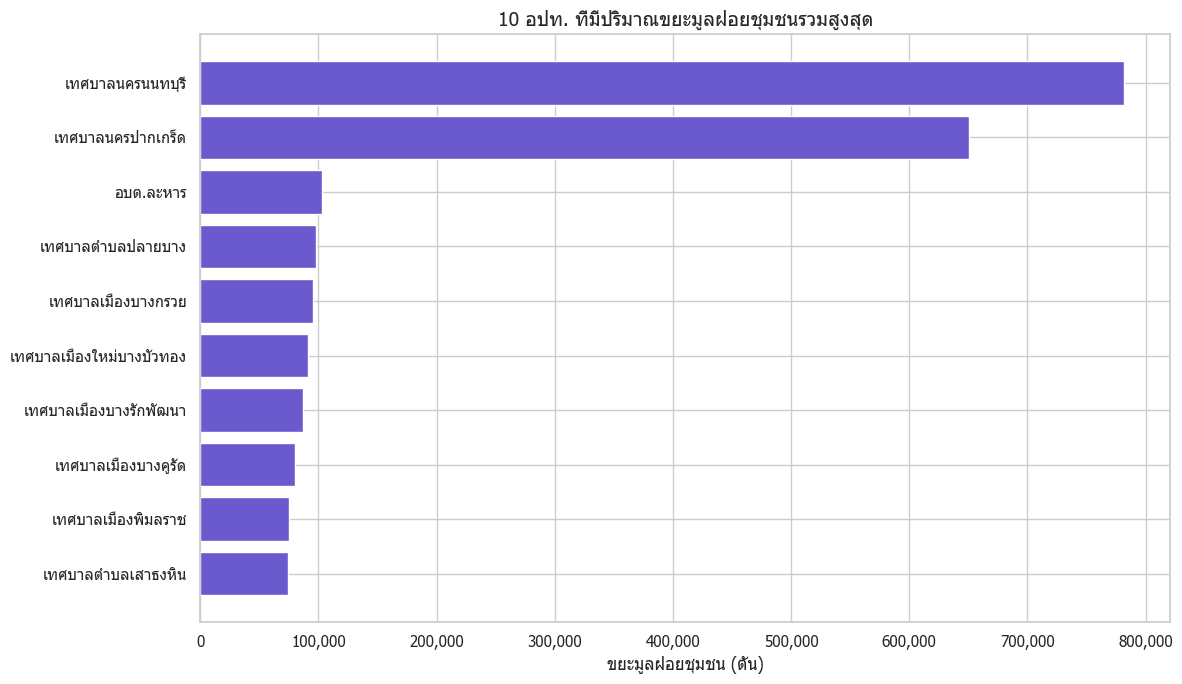

In [20]:

# Horizontal Bar: 10 อปท. ที่มีปริมาณขยะสูงสุด
top10 = df.groupby('อปท.', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(range(len(top10)), top10.values, color='slateblue', edgecolor='white')
ax.set_yticks(range(len(top10)))
ax.set_yticklabels(top10.index)
ax.set_title('10 อปท. ที่มีปริมาณขยะมูลฝอยชุมชนรวมสูงสุด', fontsize=14)
ax.set_xlabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


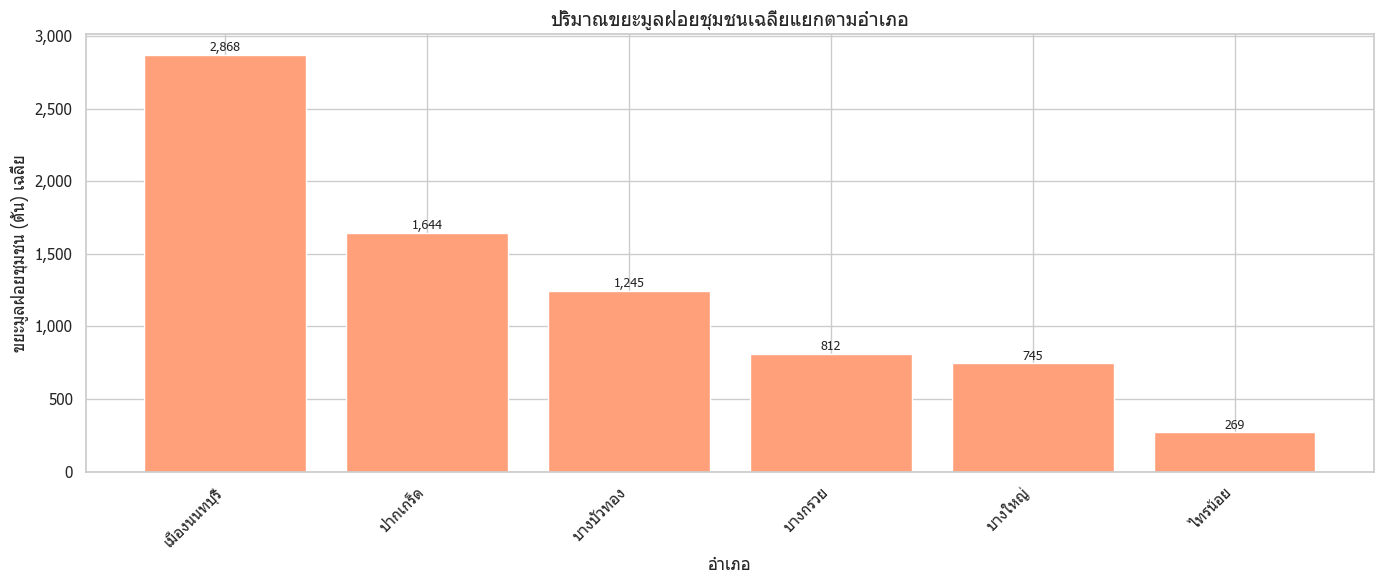

In [21]:

# Bar Chart: ปริมาณขยะมูลฝอยชุมชนเฉลี่ยแยกตามอำเภอ
district_avg = df.groupby('อำเภอ', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(len(district_avg)), district_avg.values, color='lightsalmon', edgecolor='white')
ax.set_xticks(range(len(district_avg)))
ax.set_xticklabels(district_avg.index, rotation=45, ha='right')
for i, v in enumerate(district_avg.values):
    ax.text(i, v + 5, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนเฉลี่ยแยกตามอำเภอ', fontsize=14)
ax.set_xlabel('อำเภอ')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน) เฉลี่ย')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


In [22]:

# Pie Chart: สัดส่วนขยะมูลฝอยชุมชนแยกตามอำเภอ
district_total = df.groupby('อำเภอ', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum()
fig, ax = plt.subplots(figsize=(10, 10))
wedges, texts, autotexts = ax.pie(
    district_total, labels=district_total.index, autopct='%1.1f%%',
    startangle=140, =0.8,
    colors=sns.color_palette('pastel', len(district_total))
)
for t in autotexts:
    t.set_fontsize(10)
ax.set_title('สัดส่วนขยะมูลฝอยชุมชนแยกตามอำเภอ', fontsize=14)
plt.tight_layout()
plt.show()


SyntaxError: invalid syntax (3703546956.py, line 6)

In [ ]:

# YoY: การเปลี่ยนแปลงปริมาณขยะมูลฝอยชุมชน (% Year-over-Year)
yearly = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum()
yoy = yearly.pct_change() * 100
colors = ['green' if v >= 0 else 'tomato' for v in yoy.dropna()]
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(yoy.dropna().index, yoy.dropna().values, color=colors, edgecolor='white')
ax.axhline(0, color='black', linewidth=1)
for x, y in zip(yoy.dropna().index, yoy.dropna().values):
    ax.annotate(f'{y:.1f}%', (x, y), textcoords='offset points',
                xytext=(0, 5 if y >= 0 else -15), ha='center', fontsize=10)
ax.set_title('การเปลี่ยนแปลงปริมาณขยะมูลฝอยชุมชน (% YoY)', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('การเปลี่ยนแปลง (%)')
plt.tight_layout()
plt.show()


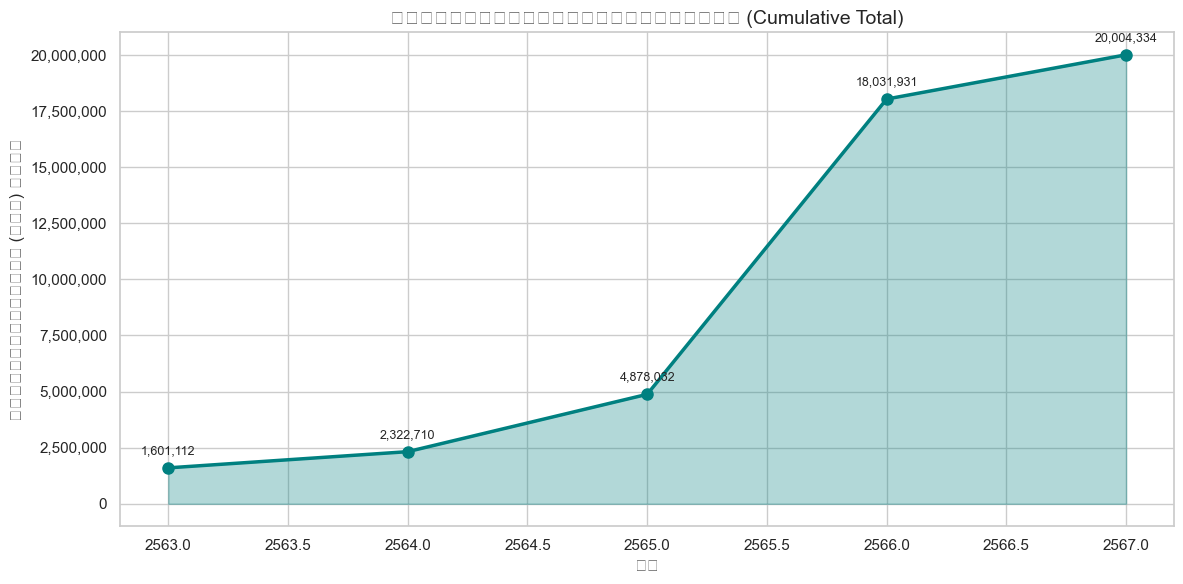

In [ ]:

# Cumulative: ปริมาณขยะมูลฝอยชุมชนสะสม
yearly_cumsum = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].sum().cumsum()
fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(yearly_cumsum.index, yearly_cumsum.values, alpha=0.3, color='teal')
ax.plot(yearly_cumsum.index, yearly_cumsum.values, marker='o', color='teal', linewidth=2.5, markersize=8)
for x, y in zip(yearly_cumsum.index, yearly_cumsum.values):
    ax.annotate(f'{y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_title('ปริมาณขยะมูลฝอยชุมชนสะสม (Cumulative Total)', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน) สะสม')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


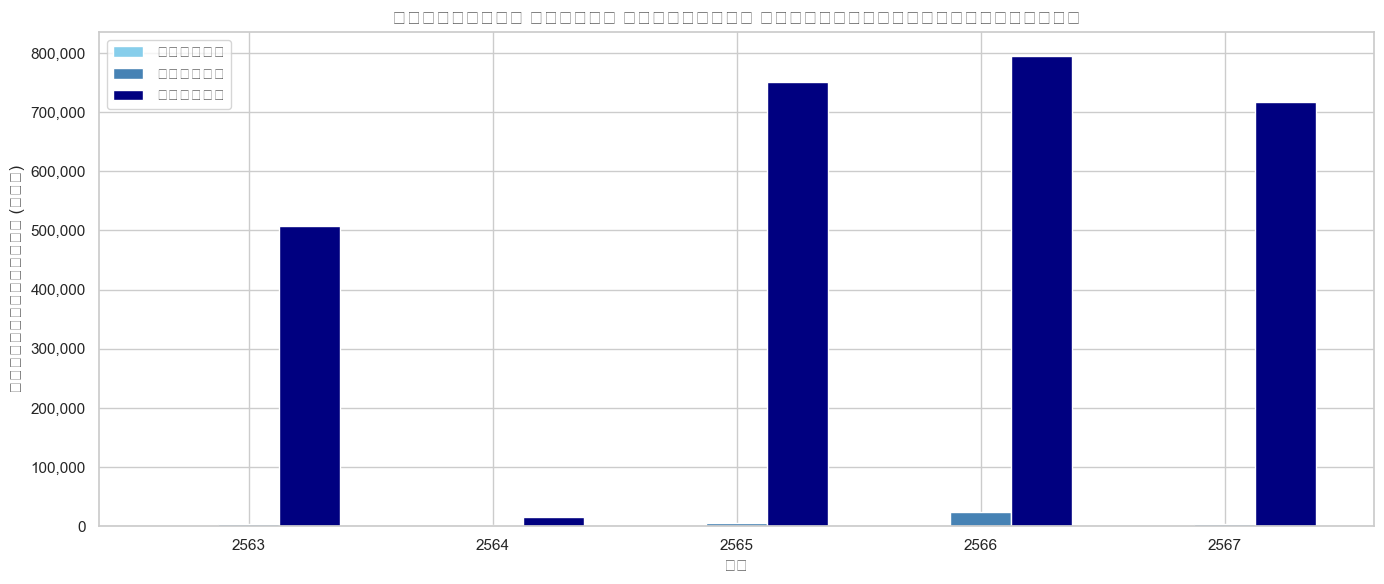

In [ ]:

# Grouped Bar: ค่าต่ำสุด เฉลี่ย สูงสุด ของขยะมูลฝอยชุมชนรายปี
yearly_stats = df.groupby('ปี')['ขยะมูลฝอยชุมชน(ตัน)'].agg(['min', 'mean', 'max'])
x = range(len(yearly_stats))
width = 0.25
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar([i - width for i in x], yearly_stats['min'],  width=width, label='ต่ำสุด',  color='skyblue',   edgecolor='white')
ax.bar(list(x),                 yearly_stats['mean'], width=width, label='เฉลี่ย', color='steelblue',  edgecolor='white')
ax.bar([i + width for i in x], yearly_stats['max'],  width=width, label='สูงสุด', color='navy',       edgecolor='white')
ax.set_xticks(list(x))
ax.set_xticklabels(yearly_stats.index)
ax.set_title('ค่าต่ำสุด เฉลี่ย และสูงสุด ของขยะมูลฝอยชุมชนรายปี', fontsize=14)
ax.set_xlabel('ปี')
ax.set_ylabel('ขยะมูลฝอยชุมชน (ตัน)')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()


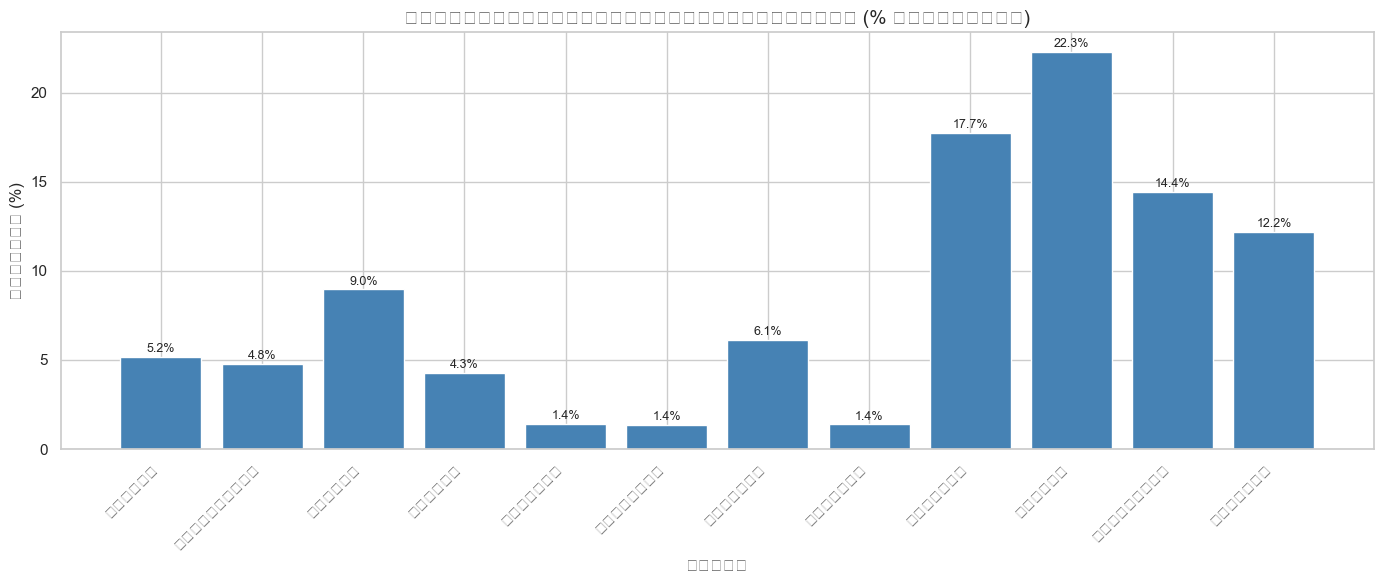

In [ ]:

# Bar Chart: สัดส่วนขยะมูลฝอยชุมชนแต่ละเดือน (% จากยอดรวมทั้งหมด)
month_order = ['มกราคม','กุมภาพันธ์','มีนาคม','เมษายน','พฤษภาคม','มิถุนายน',
               'กรกฎาคม','สิงหาคม','กันยายน','ตุลาคม','พฤศจิกายน','ธันวาคม']
monthly_total = df.groupby('เดือน', observed=True)['ขยะมูลฝอยชุมชน(ตัน)'].sum().reindex(month_order)
pct = monthly_total / monthly_total.sum() * 100
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(range(12), pct.values, color='steelblue', edgecolor='white')
ax.set_xticks(range(12))
ax.set_xticklabels(month_order, rotation=45, ha='right')
for i, v in enumerate(pct.values):
    ax.text(i, v + 0.1, f'{v:.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_title('สัดส่วนขยะมูลฝอยชุมชนแต่ละเดือน (% จากยอดรวม)', fontsize=14)
ax.set_xlabel('เดือน')
ax.set_ylabel('สัดส่วน (%)')
plt.tight_layout()
plt.show()
